# Projet Airbnb - Prédiction du prix de location

L'objectif de ce projet est de prédire le logarithme du prix (`log_price`) d'un logement Airbnb à partir de ses caractéristiques.


## Imports et chargement des données

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings
warnings.filterwarnings('ignore')

airbnb = pd.read_csv("airbnb_train.csv", on_bad_lines='skip')
airbnb_test = pd.read_csv("airbnb_test.csv", on_bad_lines='skip')

airbnb_test = airbnb_test.rename(columns={'Unnamed: 0': 'id'})

print("Taille du train :", airbnb.shape)
print("Taille du test  :", airbnb_test.shape)


Taille du train : (22234, 28)
Taille du test  : (51877, 27)


In [3]:
airbnb.head()


,id,log_price,property_type,room_type,amenities,accommodates,bathrooms,bed_type,cancellation_policy,cleaning_fee,...,last_review,latitude,longitude,name,neighbourhood,number_of_reviews,review_scores_rating,zipcode,bedrooms,beds
0,5708593,4.317488,House,Private room,"{TV,""Wireless Internet"",Kitchen,""Free parking ...",3,1.0,Real Bed,flexible,False,...,NaN,33.782712,-118.134410,Island style Spa Studio,Long Beach,0,NaN,90804,0.0,2.0
1,14483613,4.007333,House,Private room,"{""Wireless Internet"",""Air conditioning"",Kitche...",4,2.0,Real Bed,strict,False,...,2017-09-17,40.705468,-73.909439,"Beautiful and Simple Room W/2 Beds, 25 Mins to...",Ridgewood,38,86.0,11385,1.0,2.0
2,10412649,7.090077,Apartment,Entire home/apt,"{TV,""Wireless Internet"",""Air conditioning"",Kit...",6,2.0,Real Bed,flexible,False,...,NaN,38.917537,-77.031651,2br/2ba luxury condo perfect for infant / toddler,U Street Corridor,0,NaN,20009,2.0,2.0
3,17954362,3.555348,House,Private room,"{TV,""Cable TV"",Internet,""Wireless Internet"",""A...",1,1.0,Real Bed,flexible,True,...,2017-09-29,40.736001,-73.924248,Manhattan view from Queens. Lovely single room .,Sunnyside,19,96.0,11104,1.0,1.0
4,9969781,5.480639,House,Entire home/apt,"{TV,""Cable TV"",Internet,""Wireless Internet"",Ki...",4,1.0,Real Bed,moderate,True,...,2017-08-28,37.744896,-122.430665,Zen Captured Noe Valley House,Noe Valley,15,96.0,94131,2.0,2.0


# Exploration des données

Avant de construire quoi que ce soit, on regarde ce que contiennent les données. L'idée c'est de comprendre quelles variables semblent importantes pour prédire le prix, et de repérer les problèmes


### Valeurs manquantes

In [4]:
# On regarde combien de valeurs manquantes il y a par colonne
missing = airbnb.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print("Colonnes avec des valeurs manquantes :")
print(missing)


Colonnes avec des valeurs manquantes :
host_response_rate        5475
review_scores_rating      4978
first_review              4725
last_review               4716
neighbourhood             2086
zipcode                    303
host_has_profile_pic        56
host_identity_verified      56
host_since                  56
bathrooms                   51
beds                        35
bedrooms                    26
dtype: int64


On voit que `host_response_rate`, `review_scores_rating`, `first_review` et `last_review` ont beaucoup de NaN. Pour `review_scores_rating`, on remplira par la médiane. Pour les dates, on les utilisera pour calculer des features.

### Distribution de la variable cible : log_price

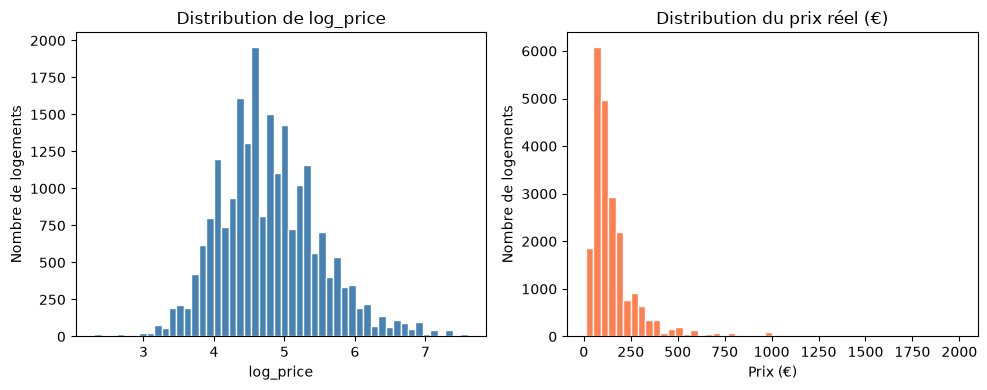

Prix médian : 110 €
Prix moyen  : 120 €


In [5]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.hist(airbnb['log_price'], bins=50, color='steelblue', edgecolor='white')
plt.title('Distribution de log_price')
plt.xlabel('log_price')
plt.ylabel('Nombre de logements')

plt.subplot(1, 2, 2)
plt.hist(np.exp(airbnb['log_price']), bins=50, color='coral', edgecolor='white')
plt.title('Distribution du prix réel (€)')
plt.xlabel('Prix (€)')
plt.ylabel('Nombre de logements')

plt.tight_layout()
plt.show()

print(f"Prix médian : {np.exp(airbnb['log_price'].median()):.0f} €")
print(f"Prix moyen  : {np.exp(airbnb['log_price'].mean()):.0f} €")


La distribution du log_price est à peu près symétrique. Le prix réel lui est très asymétrique (beaucoup de logements pas chers et quelques-uns très chers), c'est pour ca qu'on travaille avec le log.

### Impact du type de logement sur le prix

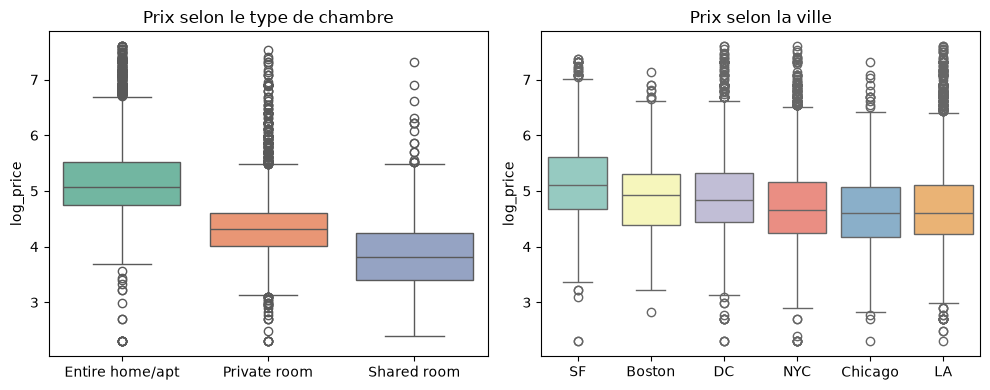

In [6]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
order = airbnb.groupby('room_type')['log_price'].median().sort_values(ascending=False).index
sns.boxplot(data=airbnb, x='room_type', y='log_price', order=order, palette='Set2')
plt.title('Prix selon le type de chambre')
plt.xlabel('')

plt.subplot(1, 2, 2)
order_city = airbnb.groupby('city')['log_price'].median().sort_values(ascending=False).index
sns.boxplot(data=airbnb, x='city', y='log_price', order=order_city, palette='Set3')
plt.title('Prix selon la ville')
plt.xlabel('')

plt.tight_layout()
plt.show()


Clairement, le type de logement et la ville ont un fort impact sur le prix :
- Un logement entier coûte en moyenne bien plus cher qu'une chambre privée
- SF et NYC ont les prix les plus élevés

Ces deux variables seront donc importantes pour le modèle.

### Corrélations des variables numériques avec le prix

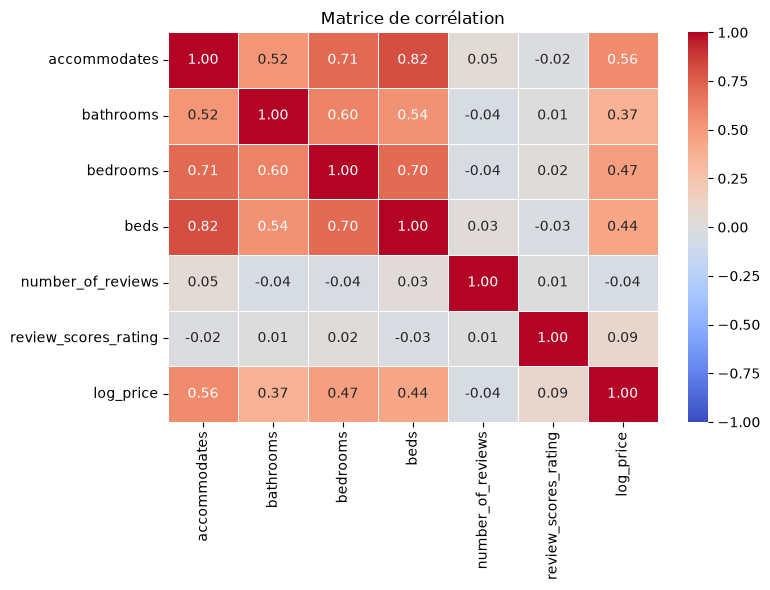

Corrélation avec log_price :
accommodates            0.564874
bedrooms                0.472871
beds                    0.435212
bathrooms               0.369118
review_scores_rating    0.092342
number_of_reviews      -0.039138
Name: log_price, dtype: float64


In [7]:
# On regarde la corrélation des variables numériques avec log_price
num_cols = ['accommodates', 'bathrooms', 'bedrooms', 'beds',
            'number_of_reviews', 'review_scores_rating', 'log_price']

corr = airbnb[num_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, linewidths=0.5)
plt.title('Matrice de corrélation')
plt.tight_layout()
plt.show()

print("Corrélation avec log_price :")
print(corr['log_price'].drop('log_price').sort_values(ascending=False))


Les variables les plus corrélées avec le prix sont `accommodates`, `bedrooms` et `bathrooms`. Plus le logement est grand, plus il est cher. Par contre `number_of_reviews` est légèrement négatif, ce qui est un peu contre-intuitif mais ça peut s'expliquer par le fait que les logements très populaires sont souvent des options pas chères.

### Analyse des équipements (amenities)

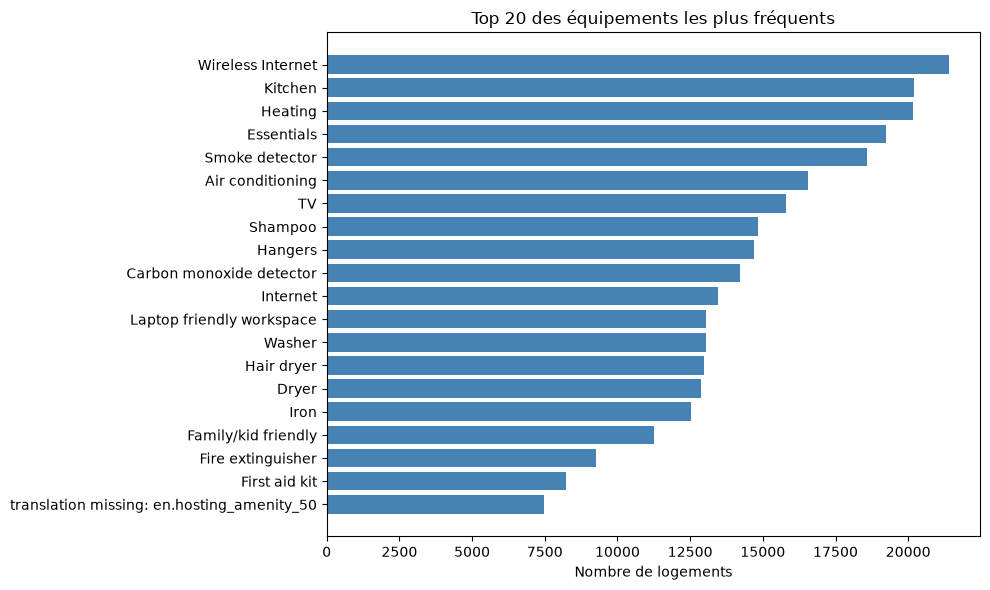

In [8]:
# La colonne amenities est une liste d'équipements sous forme de texte
# On va parser ca pour voir les équipements les plus fréquents
def parse_amenities(s):
    s = str(s).strip('{}')
    items = re.findall(r'"([^"]+)"|([^,]+)', s)
    return [a.strip() or b.strip() for a, b in items]

from collections import Counter
tous_les_amenities = []
for a in airbnb['amenities']:
    tous_les_amenities.extend(parse_amenities(a))

compteur = Counter(tous_les_amenities)
top20 = pd.DataFrame(compteur.most_common(20), columns=['equipement', 'count'])

plt.figure(figsize=(10, 6))
plt.barh(top20['equipement'][::-1], top20['count'][::-1], color='steelblue')
plt.xlabel('Nombre de logements')
plt.title('Top 20 des équipements les plus fréquents')
plt.tight_layout()
plt.show()


### Répartition géographique des prix

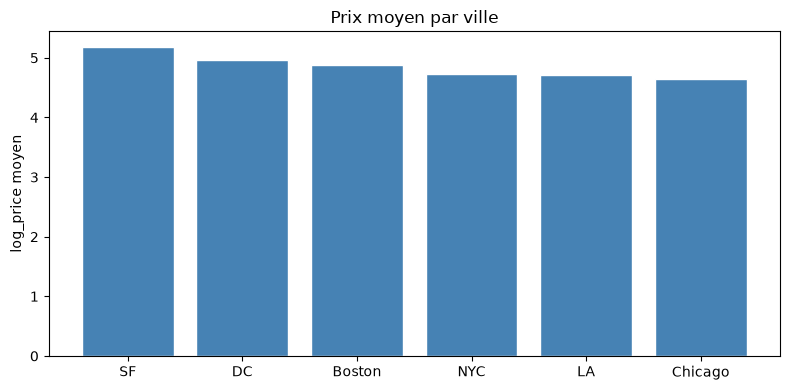

In [9]:
# Prix moyen par ville (plus lisible qu'une carte)
prix_par_ville = airbnb.groupby('city')['log_price'].mean().sort_values(ascending=False)

plt.figure(figsize=(8, 4))
plt.bar(prix_par_ville.index, prix_par_ville.values, color='steelblue', edgecolor='white')
plt.ylabel('log_price moyen')
plt.title('Prix moyen par ville')
plt.tight_layout()
plt.show()


SF est la ville avec les prix moyens les plus élevés, suivi de DC et Boston.
NYC, LA et Chicago ont des prix similaires et légèrement plus bas.
Cette différence entre villes justifie d'inclure la variable `city` dans le modèle.

# Préparation des données (Feature Engineering)

Maintenant qu'on a exploré les données, on va les préparer pour les algorithmes de machine learning.

Les étapes principales :
1. Convertir les variables binaires (True/False) en 0/1
2. Nettoyer le taux de réponse de l'hôte
3. Extraire des infos utiles des dates
4. Créer des features depuis la colonne amenities
5. Encoder les variables catégorielles en nombres
6. Gérer les valeurs manquantes

On fait une classe `Preprocesseur` pour pouvoir appliquer exactement le même traitement sur le train et le test.


In [10]:
class Preprocesseur():

    def __init__(self):
        self.fitted = False
        self.encoders = {}
        self.medianes = {}

    def fit_transform(self, dataset):
        self.fitted = True
        dataset = dataset.copy()
        dataset = self._traitement_commun(dataset, fit=True)
        return dataset

    def transform(self, dataset):
        if not self.fitted:
            raise Exception("Il faut d'abord appeler fit_transform sur le train !")
        dataset = dataset.copy()
        dataset = self._traitement_commun(dataset, fit=False)
        return dataset

    def _traitement_commun(self, dataset, fit):
        from sklearn.preprocessing import LabelEncoder

        # Variables booléennes
        bool_map = {'t': 1, 'f': 0, True: 1, False: 0, 'True': 1, 'False': 0}
        for col in ['host_has_profile_pic', 'host_identity_verified', 'instant_bookable', 'cleaning_fee']:
            dataset[col] = dataset[col].map(bool_map).fillna(0).astype(int)

        # Taux de réponse (enlever le % et convertir en float)
        dataset['host_response_rate'] = pd.to_numeric(
            dataset['host_response_rate'].astype(str).str.replace('%', '', regex=False),
            errors='coerce'
        )
        if fit:
            self.medianes['host_response_rate'] = dataset['host_response_rate'].median()
        dataset['host_response_rate'] = dataset['host_response_rate'].fillna(
            self.medianes['host_response_rate']
        )

        # Features temporelles
        for col in ['host_since', 'first_review', 'last_review']:
            dataset[col] = pd.to_datetime(dataset[col], errors='coerce')

        # Ancienneté de l'hôte sur Airbnb
        dataset['host_experience_years'] = 2025 - dataset['host_since'].dt.year
        if fit:
            self.medianes['host_experience_years'] = dataset['host_experience_years'].median()
        dataset['host_experience_years'] = dataset['host_experience_years'].fillna(
            self.medianes['host_experience_years']
        )

        # Nombre de jours depuis le dernier avis
        dataset['jours_depuis_dernier_avis'] = (
            pd.Timestamp('2025-01-01') - dataset['last_review']
        ).dt.days
        if fit:
            self.medianes['jours_depuis_dernier_avis'] = dataset['jours_depuis_dernier_avis'].median()
        dataset['jours_depuis_dernier_avis'] = dataset['jours_depuis_dernier_avis'].fillna(
            self.medianes['jours_depuis_dernier_avis']
        )

        # Est-ce que le logement a des avis (0 avis = nouveau logement)
        dataset['a_des_avis'] = (~dataset['first_review'].isna()).astype(int)

        # Amenities : extraction des équipements importants
        # On crée une colonne binaire pour chaque équipement qui semble important
        equipements_importants = [
            'TV', 'Wireless Internet', 'Air conditioning', 'Kitchen',
            'Free parking on premises', 'Washer', 'Dryer', 'Elevator',
            'Pets allowed', 'Pool', 'Gym', 'Heating', 'Cable TV',
            'Iron', 'Hair dryer', 'Shampoo', '24-hour check-in'
        ]
        for eq in equipements_importants:
            nom_col = 'eq_' + re.sub(r'[^a-z0-9]', '_', eq.lower())
            dataset[nom_col] = dataset['amenities'].apply(lambda x: int(eq in str(x)))

        # Nombre total d'équipements
        dataset['nb_equipements'] = dataset['amenities'].apply(
            lambda x: len(re.findall(r'"([^"]+)"|([^,]+)', str(x).strip('{}')))
        )

        # Nouvelles features
        # Ratio personnes par chambre (donne une idée de la densité du logement)
        dataset['personnes_par_chambre'] = dataset['accommodates'] / (dataset['bedrooms'].fillna(1) + 1)

        # Score pondéré par le nombre d'avis
        dataset['score_pondere'] = (
            dataset['review_scores_rating'].fillna(0) * np.log1p(dataset['number_of_reviews'])
        )

        # Encodage des variables catégorielles
        cols_cat = ['room_type', 'property_type', 'bed_type', 'cancellation_policy', 'city']
        for col in cols_cat:
            if fit:
                from sklearn.preprocessing import LabelEncoder
                le = LabelEncoder()
                dataset[col] = le.fit_transform(dataset[col].astype(str))
                self.encoders[col] = le
            else:
                le = self.encoders[col]
                dataset[col] = dataset[col].astype(str).apply(
                    lambda x: x if x in le.classes_ else le.classes_[0]
                )
                dataset[col] = le.transform(dataset[col])

        for col in ['bathrooms', 'bedrooms', 'beds', 'review_scores_rating']:
            if fit:
                self.medianes[col] = dataset[col].median()
            dataset[col] = dataset[col].fillna(self.medianes[col])

        # Suppression des colonnes inutilisables
        cols_a_supprimer = [
            'amenities', 'description', 'name', 'neighbourhood',
            'zipcode', 'host_since', 'first_review', 'last_review', 'id'
        ]
        dataset = dataset.drop(columns=[c for c in cols_a_supprimer if c in dataset.columns])

        return dataset


In [11]:
# Application du prétraitement
preprocesseur = Preprocesseur()

ids_test = airbnb_test['id'].copy()

# Prétraitement du train
airbnb_train_prep = preprocesseur.fit_transform(airbnb)

# Prétraitement du test
airbnb_test_prep = preprocesseur.transform(airbnb_test)

print("Train prétraité :", airbnb_train_prep.shape)
print("Test prétraité  :", airbnb_test_prep.shape)
print("\nAperçu des colonnes créées :")
print(list(airbnb_train_prep.columns))


Train prétraité : (22234, 42)
Test prétraité  : (51877, 41)

Aperçu des colonnes créées :
['log_price', 'property_type', 'room_type', 'accommodates', 'bathrooms', 'bed_type', 'cancellation_policy', 'cleaning_fee', 'city', 'host_has_profile_pic', 'host_identity_verified', 'host_response_rate', 'instant_bookable', 'latitude', 'longitude', 'number_of_reviews', 'review_scores_rating', 'bedrooms', 'beds', 'host_experience_years', 'jours_depuis_dernier_avis', 'a_des_avis', 'eq_tv', 'eq_wireless_internet', 'eq_air_conditioning', 'eq_kitchen', 'eq_free_parking_on_premises', 'eq_washer', 'eq_dryer', 'eq_elevator', 'eq_pets_allowed', 'eq_pool', 'eq_gym', 'eq_heating', 'eq_cable_tv', 'eq_iron', 'eq_hair_dryer', 'eq_shampoo', 'eq_24_hour_check_in', 'nb_equipements', 'personnes_par_chambre', 'score_pondere']


In [12]:
airbnb_train_prep.head()


,log_price,property_type,room_type,accommodates,bathrooms,bed_type,cancellation_policy,cleaning_fee,city,host_has_profile_pic,...,eq_gym,eq_heating,eq_cable_tv,eq_iron,eq_hair_dryer,eq_shampoo,eq_24_hour_check_in,nb_equipements,personnes_par_chambre,score_pondere
0,4.317488,16,1,3,1.0,4,0,0,3,1,...,0,0,0,1,1,1,0,15,3.000000,0.000000
1,4.007333,16,1,4,2.0,4,2,0,4,1,...,0,1,0,1,1,0,1,25,2.000000,315.066302
2,7.090077,0,0,6,2.0,4,0,0,2,1,...,0,1,0,0,0,1,0,20,2.000000,0.000000
3,3.555348,16,1,1,1.0,4,0,1,4,1,...,0,1,1,1,1,1,0,30,0.500000,287.590298
4,5.480639,16,0,4,1.0,4,1,1,5,1,...,0,1,1,1,1,1,1,24,1.333333,266.168517


# Modélisation

On va tester plusieurs modèles, du plus simple au plus complexe. Pour chaque modèle, on calcule le RMSE en cross-validation (5 folds). C'est le moyen le plus fiable d'évaluer un modèle sans avoir accès au vrai jeu de test.

Le RMSE mesure l'erreur moyenne de prédiction. Plus il est bas, mieux c'est.

On commence par définir une **baseline** : si on prédit juste la moyenne de log_price pour tout le monde, quel RMSE ça donne.C'est notre référence minimale.


In [13]:
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score

cols_features = [c for c in airbnb_train_prep.columns if c != 'log_price']
X = airbnb_train_prep[cols_features].fillna(0)
y = airbnb_train_prep['log_price']
X_test_final = airbnb_test_prep[cols_features].reindex(columns=X.columns, fill_value=0).fillna(0)

print(f"Nombre de features : {X.shape[1]}")
print(f"Exemples d'entraînement : {X.shape[0]}")


Nombre de features : 41
Exemples d'entraînement : 22234


### Comparaison des modèles en cross-validation

In [19]:
from sklearn.model_selection import KFold
from sklearn.base import clone
from sklearn.metrics import mean_squared_error

# Données brutes : aucune information de validation
# n'est utilisée pour ajuster le preprocessing
X_raw = airbnb.drop(columns=['log_price']).reset_index(drop=True)
y = airbnb['log_price'].reset_index(drop=True)

modeles = {
    'Baseline (moyenne)': DummyRegressor(strategy='mean'),
    'Régression Linéaire': LinearRegression(),
    'Ridge': Ridge(alpha=1.0),
    'Lasso': Lasso(alpha=0.01),
    'Arbre de décision': DecisionTreeRegressor(
        max_depth=10,
        random_state=42
    ),
    'Random Forest': RandomForestRegressor(
        n_estimators=100,
        max_depth=20,
        random_state=42,
        n_jobs=-1
    ),
    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=5,
        random_state=42
    ),
}

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

resultats = {}

print("Évaluation des modèles — 5-fold cross-validation")
print("-" * 60)

for nom, modele in modeles.items():

    rmse_folds = []

    for train_idx, val_idx in kf.split(X_raw):

        X_train_raw = X_raw.iloc[train_idx].copy()
        X_val_raw = X_raw.iloc[val_idx].copy()

        y_train = y.iloc[train_idx]
        y_val = y.iloc[val_idx]

        # Le preprocessing est appris UNIQUEMENT sur le fold train
        prep = Preprocesseur()

        X_train = prep.fit_transform(X_train_raw)
        X_val = prep.transform(X_val_raw)

        # Sécurité : même ordre de colonnes
        X_val = X_val.reindex(columns=X_train.columns, fill_value=0)

        X_train = X_train.fillna(0)
        X_val = X_val.fillna(0)

        model = clone(modele)
        model.fit(X_train, y_train)

        predictions = model.predict(X_val)

        rmse = np.sqrt(mean_squared_error(y_val, predictions))
        rmse_folds.append(rmse)

    rmse_moyen = np.mean(rmse_folds)
    rmse_std = np.std(rmse_folds)

    resultats[nom] = rmse_moyen

    print(
        f"{nom:<30} RMSE = {rmse_moyen:.4f} ± {rmse_std:.4f}"
    )


Évaluation des modèles — 5-fold cross-validation
------------------------------------------------------------
Baseline (moyenne)             RMSE = 0.7188 ± 0.0049
Régression Linéaire            RMSE = 0.4706 ± 0.0069
Ridge                          RMSE = 0.4706 ± 0.0069
Lasso                          RMSE = 0.4783 ± 0.0089
Arbre de décision              RMSE = 0.4711 ± 0.0089
Random Forest                  RMSE = 0.4061 ± 0.0090
Gradient Boosting              RMSE = 0.3932 ± 0.0077


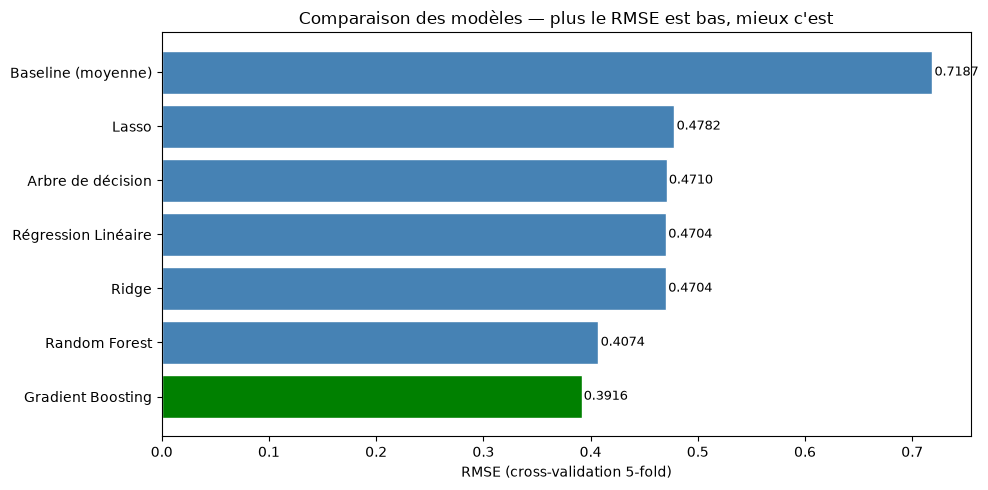


Meilleur modèle : Gradient Boosting (RMSE = 0.3916)


In [15]:
# Visualisation des résultats
df_res = pd.Series(resultats).sort_values()

plt.figure(figsize=(10, 5))
couleurs = ['green' if i == 0 else 'steelblue' for i in range(len(df_res))]
barres = plt.barh(df_res.index, df_res.values, color=couleurs, edgecolor='white')
plt.xlabel('RMSE (cross-validation 5-fold)')
plt.title('Comparaison des modèles — plus le RMSE est bas, mieux c\'est')
for i, v in enumerate(df_res.values):
    plt.text(v + 0.002, i, f'{v:.4f}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

meilleur = df_res.index[0]
print(f"\nMeilleur modèle : {meilleur} (RMSE = {df_res[meilleur]:.4f})")


Le Gradient Boosting est le meilleur modèle. C'était previsible car c'est un algorithme très puissant qui capture bien les relations non-linéaires entre les features et le prix.

La Régression Linéaire et Ridge font déjà mieux que la baseline, ce qui prouve que les features créées sont efficace. L'arbre de décision seul est moins bon que la forêt aléatoire, ce qui montre l'importance de l'ensemble de modèles.

### Analyse du meilleur modèle : Gradient Boosting

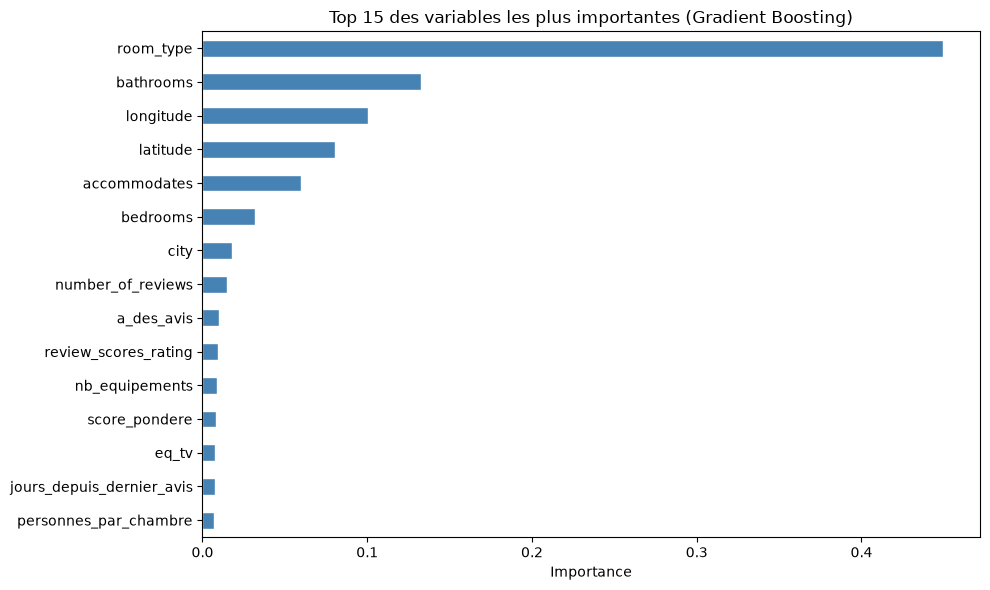

Top 10 features :
room_type               0.449455
bathrooms               0.132694
longitude               0.100298
latitude                0.080456
accommodates            0.059582
bedrooms                0.031834
city                    0.018149
number_of_reviews       0.015036
a_des_avis              0.010311
review_scores_rating    0.009147


In [16]:
# On entraîne le meilleur modèle sur tout le train pour l'analyse
meilleur_modele = GradientBoostingRegressor(
    n_estimators=200, learning_rate=0.1, max_depth=5, random_state=42
)
meilleur_modele.fit(X, y)

# Feature importances : quelles variables comptent le plus
importances = pd.Series(meilleur_modele.feature_importances_, index=cols_features)
top15 = importances.sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
top15[::-1].plot(kind='barh', color='steelblue', edgecolor='white')
plt.xlabel('Importance')
plt.title('Top 15 des variables les plus importantes (Gradient Boosting)')
plt.tight_layout()
plt.show()

print("Top 10 features :")
print(top15.head(10).to_string())


RMSE sur validation (20%) : 0.3966
R2 sur validation (20%)   : 0.6929


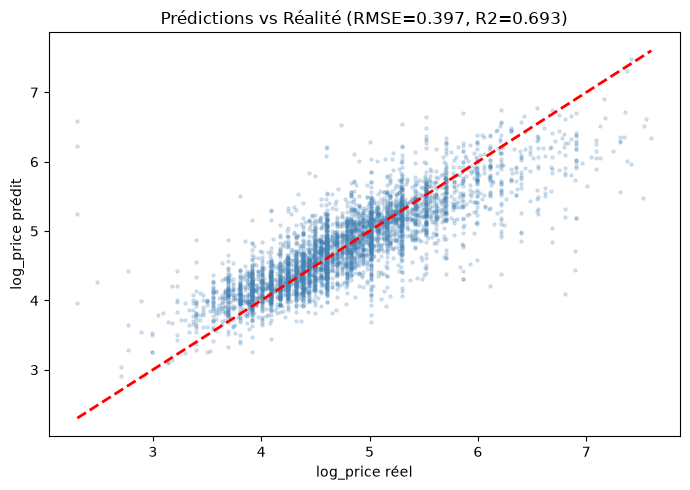

In [17]:
# Pour visualiser les performances, on fait un split train/val
X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, random_state=42)
modele_val = GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, max_depth=5, random_state=42)
modele_val.fit(X_tr, y_tr)
y_pred_val = modele_val.predict(X_val)

rmse_val = np.sqrt(np.mean((y_val - y_pred_val)**2))
r2_val   = r2_score(y_val, y_pred_val)
print(f"RMSE sur validation (20%) : {rmse_val:.4f}")
print(f"R2 sur validation (20%)   : {r2_val:.4f}")

plt.figure(figsize=(7, 5))
plt.scatter(y_val, y_pred_val, alpha=0.2, s=5, color='steelblue')
plt.plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()], 'r--', lw=2)
plt.xlabel('log_price réel')
plt.ylabel('log_price prédit')
plt.title(f'Prédictions vs Réalité (RMSE={rmse_val:.3f}, R2={r2_val:.3f})')
plt.tight_layout()
plt.show()


Le R2 d'environ 0.65 signifie que le modèle explique ~65% de la variance du prix. C'est correct pour ce type de données avec beaucoup de bruit (les prix Airbnb dépendent aussi de facteurs qu'on n'a pas comme: qualité des photos, réputation de l'hôte, événements locaux...)

## Prédiction sur le fichier de test

In [18]:
# On applique le même prétraitement
airbnb_test_complet_prep = preprocesseur.transform(airbnb_test_complet)
X_test_complet = airbnb_test_complet_prep[cols_features].reindex(columns=X.columns, fill_value=0).fillna(0)

# Prédiction sur les 51 877 logements
y_pred_final = meilleur_modele.predict(X_test_complet)
print(f"Nombre de prédictions : {len(y_pred_final)}")

NameError: name 'airbnb_test_complet' is not defined

## Sauvegarde dans le fichier de prédiction

In [ ]:
prediction_example = pd.read_csv("prediction_example.csv")
prediction_example["logpred"] = y_pred_final
prediction_example.to_csv("MaPredictionFinale.csv", index=False)


## Vérification du fichier

In [ ]:
def estConforme(monFichier_csv):
    votre_prediction = pd.read_csv(monFichier_csv)
    fichier_exemple  = pd.read_csv("prediction_example.csv")

    assert votre_prediction.columns[1] == fichier_exemple.columns[1], \
        f"Attention, votre colonne de prédiction doit s'appeler {fichier_exemple.columns[1]}, elle s'appelle '{votre_prediction.columns[1]}'"
    assert len(votre_prediction) == len(fichier_exemple), \
        f"Attention, vous devriez avoir {len(fichier_exemple)} prédictions dans votre fichier, il en contient '{len(votre_prediction)}'"
    assert np.all(votre_prediction.iloc[:, 0] == fichier_exemple.iloc[:, 0])

    print("Fichier conforme!")

estConforme("MaPredictionFinale.csv")


Fichier conforme!
